# NB3 · Multi-scale residual detector, residual hierarchy and end model

Guide sections "Detector: multi-scale graph model, scores and fusion" and "Label model and end model" (eq. 12–16).
Inputs come from rule engine v1 (`src/rules_v1.py`) and the label model (`results/labels_v1/q.csv`).

**Pipeline**

1. **Predict** each zone's relative level ρ (eq. 2) out of sample, with LightGBM (Huber loss), two-fold cross-fitted in time and trained on rule-clean steps only (masked loss).
   - Two predictors: **forecast** = own masked past + calendar; **nowcast** = forecast + the *current* ρ of every other zone (the guide's leave-one-zone-out graph input).
   - A classical baseline: **STL** residual (statsmodels).
2. **Multi-scale:** MODWT (LA8 from PyWavelets, J = 4) of the residual, **phase-aligned** by each band's measured group delay. Bands W1–W4 (20 min – 5.3 h) and the smooth V4. Scores start after a 21-day warm-up.
3. **Residual hierarchy** (eq. 14): region g, city u, zone v, per band. **Level scores** (eq. 15): robust z over a trailing 28-day window, estimated on rule-clean steps.
4. **Which residual carries the hierarchy?** Each rule item should peak at the level its structure implies: multi-city → g, whole city → u, one zone → v.
5. **Detector flags:** zone-step max score > γ, with γ = 99.5th percentile on rule-negative steps (away from rule events by more than half the widest band's support). Then detector recall of rule items, and **detector-only candidates** (anomalies no rule covers), described as partial drops, surges or other shapes.
6. **End model** (eq. 12):
   - soft-label LightGBM and a 2-layer MLP on unified item features (structure, states, ρ dynamics, calendar, episode context, detector scores);
   - trained on rule items (targets q from NB2) plus sampled **normal windows** (target N), out of fold by episode;
   - it then predicts the detector-only candidates.
7. **Fusion** (eq. 16): p ∝ q^β f^(1−β), β = 0.5 until NB4 tunes it on injected data. The end model abstains (p = q) on items whose label-model class has less than 3 items of training mass.

**Design decisions** (details in `docs/decisions.md`):

| # | Decision |
|---|---|
| D39 | LightGBM nowcasts (the guide's fallback) instead of the TCN-GAT, with an automatic scikit-learn fallback if LightGBM's native library fails |
| D40 | Forecast vs graph-nowcast residual, compared empirically |
| D41 | Two-fold temporal cross-fitting |
| D42 | Causal MODWT |
| D43 | γ estimation |
| D44 | Detector-only candidate extraction |
| D45 | Normal windows |
| D46 | Clock and transfer items keep the label-model q |
| D47 | Out-of-fold end model by episode |
| D50 | End-model abstention on low-support classes in fusion |

**Run on Colab:** copy the repository to `MyDrive/grid-event-or-data-artefact/` and run all cells. The first cell installs `lightgbm`, `PyWavelets` and `statsmodels` if missing. Runtime is about 10–15 min on a standard Colab CPU.

In [1]:
import sys, subprocess, importlib, json, time
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
for pkg, mod in [("lightgbm", "lightgbm"), ("PyWavelets", "pywt"), ("statsmodels", "statsmodels"), ("openpyxl", "openpyxl")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/grid-event-or-data-artefact")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import Patch
import lightgbm, pywt, statsmodels
import rules_v1 as R1, detector as D, end_model as EM, viz
from viz import COL, LABEL_COL, savefig
LABEL_COL = {**LABEL_COL, "N": "#9AA0A6"}

XLSX = ROOT / "data" / "raw" / "Data Morocco.xlsx"
OUT_D = ROOT / "results" / "detector_v1"; OUT_D.mkdir(parents=True, exist_ok=True)
OUT_E = ROOT / "results" / "end_model_v1"; OUT_E.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "results" / "figures"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
print("ROOT =", ROOT, "| lightgbm", lightgbm.__version__, "| pywt", pywt.__version__, "| statsmodels", statsmodels.__version__)
T0 = time.time()

Mounted at /content/drive
ROOT = /content/drive/MyDrive/grid-event-or-data-artefact | lightgbm 4.6.0 | pywt 1.8.0 | statsmodels 0.15.0


## 1. Rule-engine states and items (identical to `results/catalogue_v1`), label-model q

In [2]:
res = R1.build(XLSX)
items = res["items"]
cat = pd.read_csv(ROOT / "results" / "catalogue_v1" / "items.csv", parse_dates=["start", "end"])
assert (items.item_id.values == cat.item_id.values).all() and (items.start.values == cat.start.values).all(), "rule engine output differs from catalogue_v1"
q = pd.read_csv(ROOT / "results" / "labels_v1" / "q.csv", parse_dates=["start", "end"])
assert (q.item_id.values == items.item_id.values).all()
zr = res["zone_runs"]
PAN = {s: D.build_panel(res["data"], res["exp"], res["masks"], s) for s in ["south", "Marrakech"]}
for s, P in PAN.items():
    print(f"{s}: {P['rho'].shape}, masked share {P['mask'].to_numpy().mean():.4f}")

south: (88890, 15), masked share 0.0139
Marrakech: (17520, 2), masked share 0.0316


## 2. Predictors: forecast vs graph nowcast vs STL (out of sample, rule-clean steps)

In [3]:
PRED = {}
for s, P in PAN.items():
    t = time.time()
    PRED[(s, "forecast")] = D.predict_rho(P, "forecast")
    PRED[(s, "nowcast")] = D.predict_rho(P, "nowcast")
    print(f"{s}: predictors fitted in {time.time() - t:.0f} s with backend = {P.get('backend')}")
STL_RES = D.stl_residual(PAN["south"])
BACKEND = PAN["south"].get("backend")

rows = []
for s, P in PAN.items():
    clean = ~P["mask"]
    res_ = {"forecast": P["rho"] - PRED[(s, "forecast")], "nowcast": P["rho"] - PRED[(s, "nowcast")], "expected (rho_hat = 1)": P["rho"] - 1}
    if s == "south": res_["STL"] = STL_RES
    for name, E in res_.items():
        Ec = E.where(clean)
        for per, sel in [("all", slice(None)), ("Jul 2023 +", Ec.index >= D.SPLIT)]:
            v = Ec.loc[sel].abs().stack()
            rows.append(dict(system=s, residual=name, period=per, MAE=v.mean(), median_abs=v.median(), RMSE=np.sqrt((v ** 2).mean())))
pred_metrics = pd.DataFrame(rows).round(4)
pred_metrics.to_csv(OUT_D / "predictor_metrics.csv", index=False)
lb = D.ljung_box(PAN["south"]["rho"] - PRED[("south", "forecast")], PAN["south"]["mask"], [1, 144]).assign(residual="forecast")
lb = pd.concat([lb, D.ljung_box(PAN["south"]["rho"] - PRED[("south", "nowcast")], PAN["south"]["mask"], [1, 144]).assign(residual="nowcast")])
lb.to_csv(OUT_D / "ljung_box.csv", index=False)
print("Ljung-Box (statsmodels), median over zones:"); print(lb.groupby("residual")[["acf_lag1", "lb_stat_1", "lb_stat_144"]].median())
pred_metrics.pivot_table(index=["system", "residual"], columns="period", values="MAE")

south: predictors fitted in 242 s with backend = lightgbm
Marrakech: predictors fitted in 9 s with backend = lightgbm
Ljung-Box (statsmodels), median over zones:
          acf_lag1  lb_stat_1  lb_stat_144
residual                                  
forecast     0.179     2812.3      11502.2
nowcast      0.194     3292.8      13867.5


period                            Jul 2023 +     all
system    residual                                  
Marrakech expected (rho_hat = 1)      0.2673  0.2755
          forecast                    0.0920  0.1076
          nowcast                     0.0925  0.1077
south     STL                         0.0589  0.0594
          expected (rho_hat = 1)      0.1796  0.1835
          forecast                    0.0278  0.0288
          nowcast                     0.0282  0.0292

saved /content/drive/MyDrive/grid-event-or-data-artefact/results/figures/E16_predictor_example.png


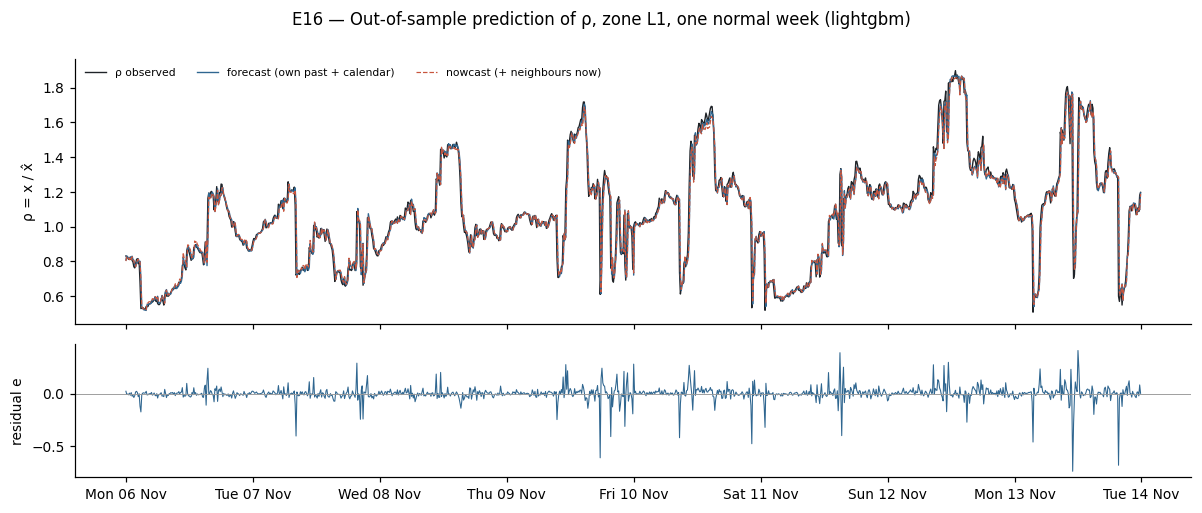

In [4]:
P = PAN["south"]; z = "L1"; a, b = "2023-11-06", "2023-11-13"
fig, axs = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
axs[0].plot(P["rho"][z][a:b], color=COL["trace"], lw=.9, label="ρ observed")
axs[0].plot(PRED[("south", "forecast")][z][a:b], color="#2F6690", lw=.9, label="forecast (own past + calendar)")
axs[0].plot(PRED[("south", "nowcast")][z][a:b], color="#C8553D", lw=.8, ls="--", label="nowcast (+ neighbours now)")
axs[0].set_ylabel("ρ = x / x̂"); axs[0].legend(fontsize=7, ncol=3)
axs[1].plot((P["rho"][z] - PRED[("south", "forecast")][z])[a:b], color="#2F6690", lw=.7)
axs[1].axhline(0, color="#999", lw=.6); axs[1].set_ylabel("residual e")
axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
fig.suptitle(f"E16 — Out-of-sample prediction of ρ, zone {z}, one normal week ({BACKEND})", y=1.0)
fig.tight_layout(); savefig(fig, FIG, "E16_predictor_example"); plt.show()

## 3. Multi-scale level scores and the residual-hierarchy test (D40)
For every southern rule item (dead and fill), take the maximum raw-band score of g, u (the item's cities) and v (the item's zones) over the item's span. The **expected** level comes from the item's structure: multi-city → g, ≥ 90 % of one city → u, one zone → v. A residual "carries the hierarchy" if the top-scoring level matches.

In [5]:
SC = {}
t = time.time()
for s, P in PAN.items():
    SC[(s, "forecast")] = D.level_scores(P, P["rho"] - PRED[(s, "forecast")])                       # all 6 bands
    SC[(s, "nowcast")] = D.level_scores(P, P["rho"] - PRED[(s, "nowcast")], bands_used=["raw"])    # raw band only
SC[("south", "STL")] = D.level_scores(PAN["south"], STL_RES, bands_used=["raw"])
print(f"scores in {time.time() - t:.0f} s")

P = PAN["south"]
ncity = {c: sum(1 for z in P["rho"].columns if P["city"][z] == c) for c in set(P["city"].values())}
south_items = items[(items.system == "south") & items.kind.isin(["dead", "fill"])].copy()
def expected_level(r):
    if r.n_cities >= 2: return "g"
    if r.n_zones >= 2: return "u" if r.n_zones / ncity[r.cities] >= 0.9 else None
    return "v"
south_items["expected_level"] = [expected_level(r) for r in south_items.itertuples()]
south_items.loc[south_items.start < PAN["south"]["rho"].index[0] + pd.Timedelta(days=D.WARMUP_DAYS), "expected_level"] = None   # no scores in the warm-up
print("items in the 21-day warm-up (not scored):", int((south_items.start < PAN["south"]["rho"].index[0] + pd.Timedelta(days=D.WARMUP_DAYS)).sum()))
for name in ["forecast", "nowcast", "STL"]:
    S = SC[("south", name)]["raw"]; tops, gm = [], []
    for r in south_items.itertuples():
        sl = slice(r.start, r.end - pd.Timedelta("10min")); zs = r.zones.split(","); cs = sorted(set(P["city"][z] for z in zs))
        vals = [S["g"][sl].max(), S["u"].loc[sl, cs].max().max(), S["v"].loc[sl, zs].max().max()]
        tops.append("guv"[int(np.nanargmax(vals))] if np.isfinite(vals).any() else None); gm.append(vals[0])   # None: inside the warm-up
    south_items[f"top_{name}"] = tops; south_items[f"gmax_{name}"] = gm
ok = south_items.expected_level.notna()
hier = pd.DataFrame([{**{"residual": n, "all": (south_items.loc[ok, f"top_{n}"] == south_items.loc[ok, "expected_level"]).mean()},
                      **{f"level {lv} (n={int((south_items.expected_level == lv).sum())})": (south_items.loc[south_items.expected_level == lv, f"top_{n}"] == lv).mean() for lv in "guv"}}
                     for n in ["forecast", "nowcast", "STL"]]).round(3)
hier.to_csv(OUT_D / "hierarchy_consistency.csv", index=False)
hier_kind = pd.DataFrame([{"residual": n, "kind": k, "level": lv, "n": int(((south_items.kind == k) & (south_items.expected_level == lv)).sum()),
                           "correct": (south_items.loc[(south_items.kind == k) & (south_items.expected_level == lv), f"top_{n}"] == lv).mean()}
                          for n in ["forecast", "nowcast", "STL"] for k in ["dead", "fill"] for lv in "guv"]).round(3)
hier_kind = hier_kind[hier_kind.n > 0]
hier_kind.to_csv(OUT_D / "hierarchy_consistency_by_kind.csv", index=False)
print(hier_kind.pivot_table(index=["kind", "level", "n"], columns="residual", values="correct").to_string())
print(south_items[south_items.expected_level.isin(["g", "u"])][["item_id", "kind", "start", "zones", "expected_level", "top_forecast", "top_nowcast", "top_STL", "gmax_forecast", "gmax_nowcast"]].round(1).to_string(index=False))
hier

scores in 24 s
items in the 21-day warm-up (not scored): 11
residual         STL  forecast  nowcast
kind level n                           
dead g     3   1.000     1.000    1.000
     v     71  0.915     0.958    0.958
fill g     6   0.167     0.167    0.167
     u     40  0.125     0.350    0.375
     v     86  0.814     0.849    0.884
item_id kind               start                                        zones expected_level top_forecast top_nowcast top_STL  gmax_forecast  gmax_nowcast
   D077 dead 2023-01-28 21:10:00 B1,B2,B3,F1,F2,F3,F4,F5,F6,F7,L1,L2,L3,L4,L5              g            g           g       g          214.2         230.6
   D096 dead 2023-07-16 14:50:00                B1,B2,B3,F1,F2,F3,F4,F5,F6,F7              g            g           g       g          230.9         235.6
   D117 dead 2024-03-31 11:10:00       B1,B2,B3,F1,F2,F3,F4,F5,F6,F7,L3,L4,L5              g            g           g       g          174.7         178.7
   F028 fill 2022-10-25 13:10:00        

,residual,all,level g (n=9),level u (n=40),level v (n=157)
0,forecast,0.772,0.444,0.350,0.898
1,nowcast,0.791,0.444,0.375,0.917
2,STL,0.699,0.444,0.125,0.860


In [6]:
MAIN = "forecast"   # the residual that carries the region / city / zone hierarchy (D40; see the table above)
print("main residual for scores and features:", MAIN)

main residual for scores and features: forecast


## Fig. 8 — Residual hierarchy during the Jan 2023 logger episode (C05/C06) vs a feeder outage (C02)

saved /content/drive/MyDrive/grid-event-or-data-artefact/results/figures/fig8_residual_hierarchy.png


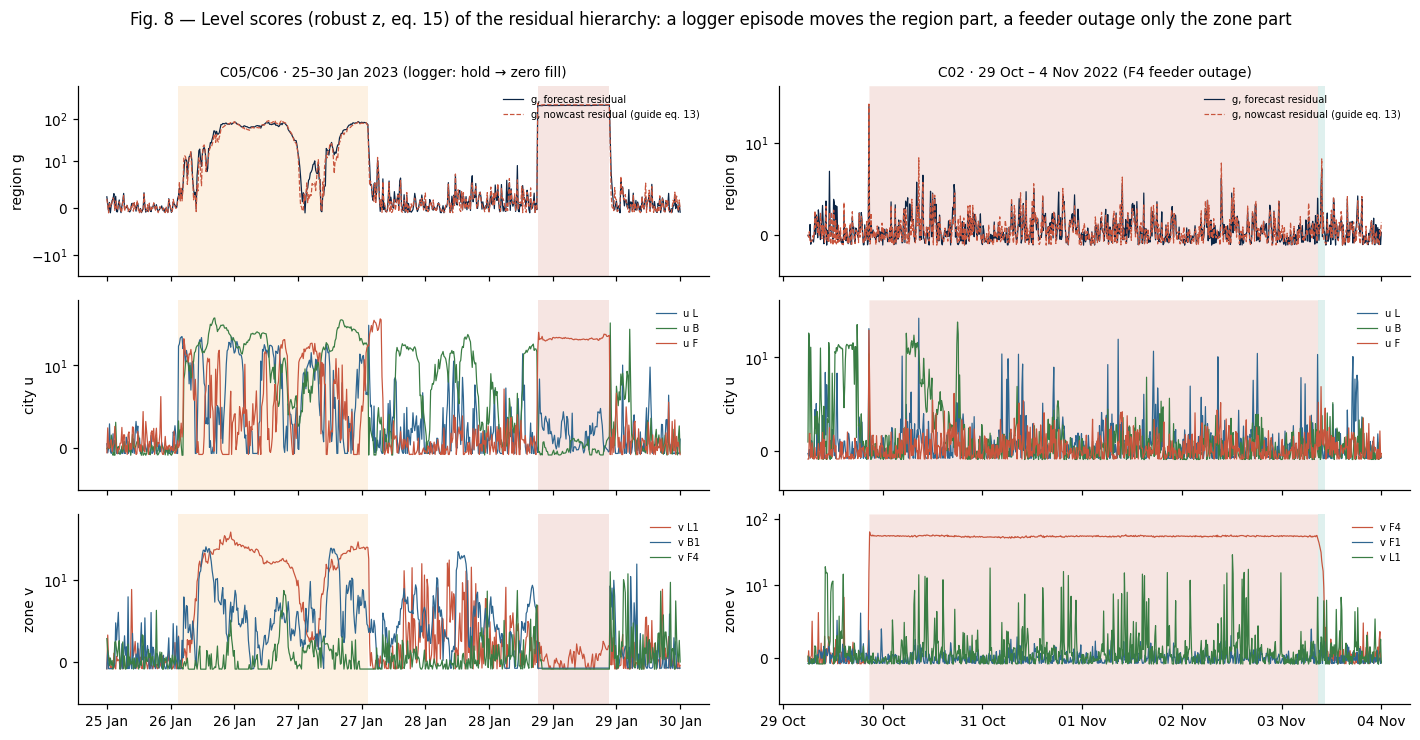

In [7]:
P = PAN["south"]; Sf = SC[("south", "forecast")]["raw"]; Sn = SC[("south", "nowcast")]["raw"]
cases = [("C05/C06 · 25–30 Jan 2023 (logger: hold → zero fill)", "2023-01-25 12:00", "2023-01-30 00:00", ["L1", "B1", "F4"]),
         ("C02 · 29 Oct – 4 Nov 2022 (F4 feeder outage)", "2022-10-29 06:00", "2022-11-04 00:00", ["F4", "F1", "L1"])]
fig, axs = plt.subplots(3, 2, figsize=(13, 6.6), sharex="col")
for col, (title, a, b, zs) in enumerate(cases):
    axs[0, col].plot(Sf["g"][a:b], color="#0B2545", lw=.8, label="g, forecast residual")
    axs[0, col].plot(Sn["g"][a:b], color="#C8553D", lw=.8, ls="--", label="g, nowcast residual (guide eq. 13)")
    axs[0, col].set_ylabel("region g"); axs[0, col].set_title(title, fontsize=9)
    for c, colr in zip(["Laayoune", "Boujdour", "Foum eloued"], ["#2F6690", "#3A7D44", "#C8553D"]):
        axs[1, col].plot(Sf["u"][c][a:b], color=colr, lw=.8, label=f"u {viz.CITY_SHORT[c]}")
    axs[1, col].set_ylabel("city u")
    for z, colr in zip(zs, ["#C8553D", "#2F6690", "#3A7D44"]):
        axs[2, col].plot(Sf["v"][z][a:b], color=colr, lw=.8, label=f"v {z}")
    axs[2, col].set_ylabel("zone v"); axs[2, col].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    for r_ in range(3):
        axs[r_, col].set_yscale("symlog", linthresh=10); axs[r_, col].legend(fontsize=6.5, loc="upper right")
        for st in ["dead", "hold", "interp"]:
            m = P["states"][st][zs[0]][a:b]
            axs[r_, col].fill_between(m.index, 0, 1, where=m.to_numpy(), step="post", color=COL["zero" if st == "dead" else st], alpha=.15, lw=0, transform=axs[r_, col].get_xaxis_transform())
fig.suptitle("Fig. 8 — Level scores (robust z, eq. 15) of the residual hierarchy: a logger episode moves the region part, a feeder outage only the zone part", y=1.01)
fig.tight_layout(); savefig(fig, FIG, "fig8_residual_hierarchy"); plt.show()

## 4. Detector flags, recall of rule items, detector-only candidates
Zone-step score Z = max over bands and over the levels containing the zone (g, its city's u, its own v).
γ = 99.5th percentile of Z on **rule-negative** zone-steps (not in any rule state, within the data range), so 0.5 % of clean zone-steps are flagged by construction.

In [8]:
ZMAX, GAMMA, NEG = {}, {}, {}
w = 2 * D.SPILL_STEPS + 1
for s, P in PAN.items():
    Z = D.zone_max_score(P, SC[(s, MAIN)])
    ZMAX[s] = Z
    M = P["mask"].astype(float)
    near_own = M.rolling(w, center=True, min_periods=1).max() > 0                       # this zone near a rule state
    near_multi = (M.sum(axis=1) >= 2).astype(float).rolling(w, center=True, min_periods=1).max() > 0   # system near a multi-zone state
    neg = (~near_own) & (~near_multi.to_numpy()[:, None]) & Z.notna()
    NEG[s] = neg
    GAMMA[s] = float(np.nanpercentile(Z.where(neg).to_numpy(), 99.5))
    print(f"{s}: rule-negative zone-steps {int(neg.to_numpy().sum()):,} of {Z.notna().to_numpy().sum():,}; gamma = {GAMMA[s]:.2f}")

rec = []
for r in q[q.kind.isin(["dead", "fill"])].itertuples():
    Z = ZMAX[r.system]; zs = r.zones.split(",")
    zmax = Z.loc[r.start:r.end - pd.Timedelta(minutes=PAN[r.system]["step"]), zs].max().max()
    rec.append(dict(item_id=r.item_id, system=r.system, label=r.label, zmax=zmax, detected=bool(zmax > GAMMA[r.system])))
rec = pd.DataFrame(rec)
recall = rec.groupby(["system", "label"]).agg(items=("item_id", "size"), detected=("detected", "mean"), median_score=("zmax", "median")).round(3)
recall.to_csv(OUT_D / "detector_recall_of_rule_items.csv")
recall

south: rule-negative zone-steps 1,129,478 of 1,257,663; gamma = 33.35
Marrakech: rule-negative zone-steps 30,270 of 35,040; gamma = 16.88


items  detected  median_score
system    label                               
Marrakech A3         7     0.000         4.946
          G3        35     0.086         9.590
          G4        13     0.077        11.738
south     A1         3     1.000       570.682
          A2        57     0.737        59.501
          A3        88     0.511        73.344
          G2         1     0.000           NaN
          G3        18     0.944       148.630
          G4        56     0.946       113.476
          N          3     1.000       139.393

323 detector-only candidates; {'Marrakech': 7, 'south': 316}
by number of zones: {1: 305, 2: 15, 3: 1, 5: 1, 15: 1}
duration (h) quantiles: {0.1: 0.5, 0.5: 1.33, 0.9: 5.63}
saved /content/drive/MyDrive/grid-event-or-data-artefact/results/figures/E17_detector_only_candidates.png


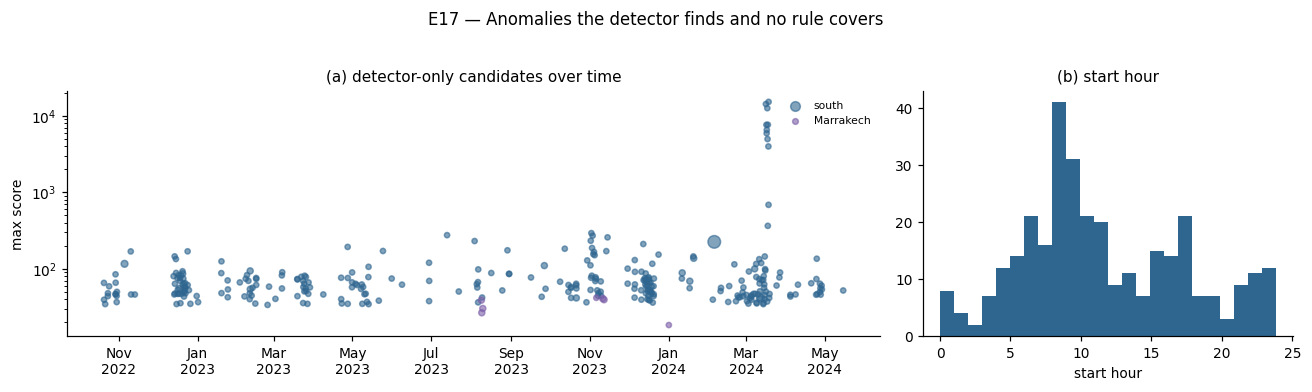

In [9]:
DET = []
for s, P in PAN.items():
    d = EM.detector_items(P, ZMAX[s], GAMMA[s], zr)
    DET.append(d)
det = pd.concat(DET, ignore_index=True).sort_values("start").reset_index(drop=True)
det.insert(0, "item_id", [f"X{i:03d}" for i in range(len(det))])
det.to_csv(OUT_D / "detector_items.csv", index=False)
print(len(det), "detector-only candidates;", det.groupby("system").size().to_dict())
print("by number of zones:", det.n_zones.value_counts().sort_index().to_dict())
print("duration (h) quantiles:", det.duration_h.quantile([.1, .5, .9]).round(2).to_dict())

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw=dict(width_ratios=[2.2, 1]))
for s, col in [("south", "#2F6690"), ("Marrakech", "#7B5EA7")]:
    d = det[det.system == s]
    axs[0].scatter(d.start, d.max_score, s=8 + 4 * d.n_zones, color=col, alpha=.6, label=s)
axs[0].set_yscale("log"); axs[0].set_ylabel("max score"); axs[0].legend(fontsize=7); axs[0].set_title("(a) detector-only candidates over time")
axs[0].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axs[1].hist(det.start.dt.hour + det.start.dt.minute / 60, bins=24, color="#2F6690"); axs[1].set_xlabel("start hour"); axs[1].set_title("(b) start hour")
fig.suptitle("E17 — Anomalies the detector finds and no rule covers", y=1.03)
fig.tight_layout(); savefig(fig, FIG, "E17_detector_only_candidates"); plt.show()

## 5. Normal windows (D45) and unified item features

In [10]:
rng = np.random.default_rng(0)
ev = items[items.kind.isin(["dead", "fill"])]
dur_pool = ev.duration_h.clip(upper=48).to_numpy()
NW = []
for s, n in [("south", 250), ("Marrakech", 50)]:
    P = PAN[s]
    busy = P["mask"] | (ZMAX[s] > GAMMA[s]) | P["rho"].isna()
    e_s = ev[ev.system == s]
    pats = np.where(e_s.n_cities >= 2, "all", np.where(e_s.n_zones >= 2, "city", "zone"))
    NW.append(EM.normal_windows(P, busy, n, rng, dur_pool, pats))
nw = pd.concat(NW, ignore_index=True)
nw.insert(0, "item_id", [f"N{i:03d}" for i in range(len(nw))])
nw.to_csv(OUT_E / "normal_windows.csv", index=False)
print(len(nw), "normal windows;", nw.groupby(["system", "n_cities"]).size().to_dict())

epi = EM.episode_info(items)
FEAT = []
for s, P in PAN.items():
    Snb = SC[(s, "nowcast")]["raw"]["v"]
    for part in [ev[ev.system == s], nw[nw.system == s], det[det.system == s]]:
        if len(part):
            FEAT.append(EM.item_features(P, SC[(s, MAIN)], Snb, part, zr, epi).assign(system=s))
feat = pd.concat(FEAT, ignore_index=True)
feat["source"] = feat.item_id.str[0].map({"D": "rule", "F": "rule", "N": "normal", "X": "detector"})
feat.to_csv(OUT_E / "item_features.csv", index=False)
print(feat.groupby("source").size().to_dict(), "| features:", feat.shape[1] - 3)

300 normal windows; {('Marrakech', 1): 50, ('south', 1): 245, ('south', 3): 5}
{'detector': 323, 'normal': 300, 'rule': 281} | features: 43


### What the detector finds that no rule covers
Descriptive bins for detector-only candidates (not types):
- **partial drop**: mean ρ < 0.7 and minimum ρ < 0.5, i.e. load well below expected but above the dead threshold;
- **surge**: mean ρ > 1.4;
- **other**: a shape change at roughly normal level.

                          n  median_h  median_rho  n_multizone
system    nature                                              
Marrakech other           4      1.75        0.97            2
          surge           3      2.00        1.63            3
south     other         152      1.08        1.00           12
          partial drop   27      1.33        0.50            0
          surge         137      2.00        1.82            1
saved /content/drive/MyDrive/grid-event-or-data-artefact/results/figures/E18_detector_only_gallery.png


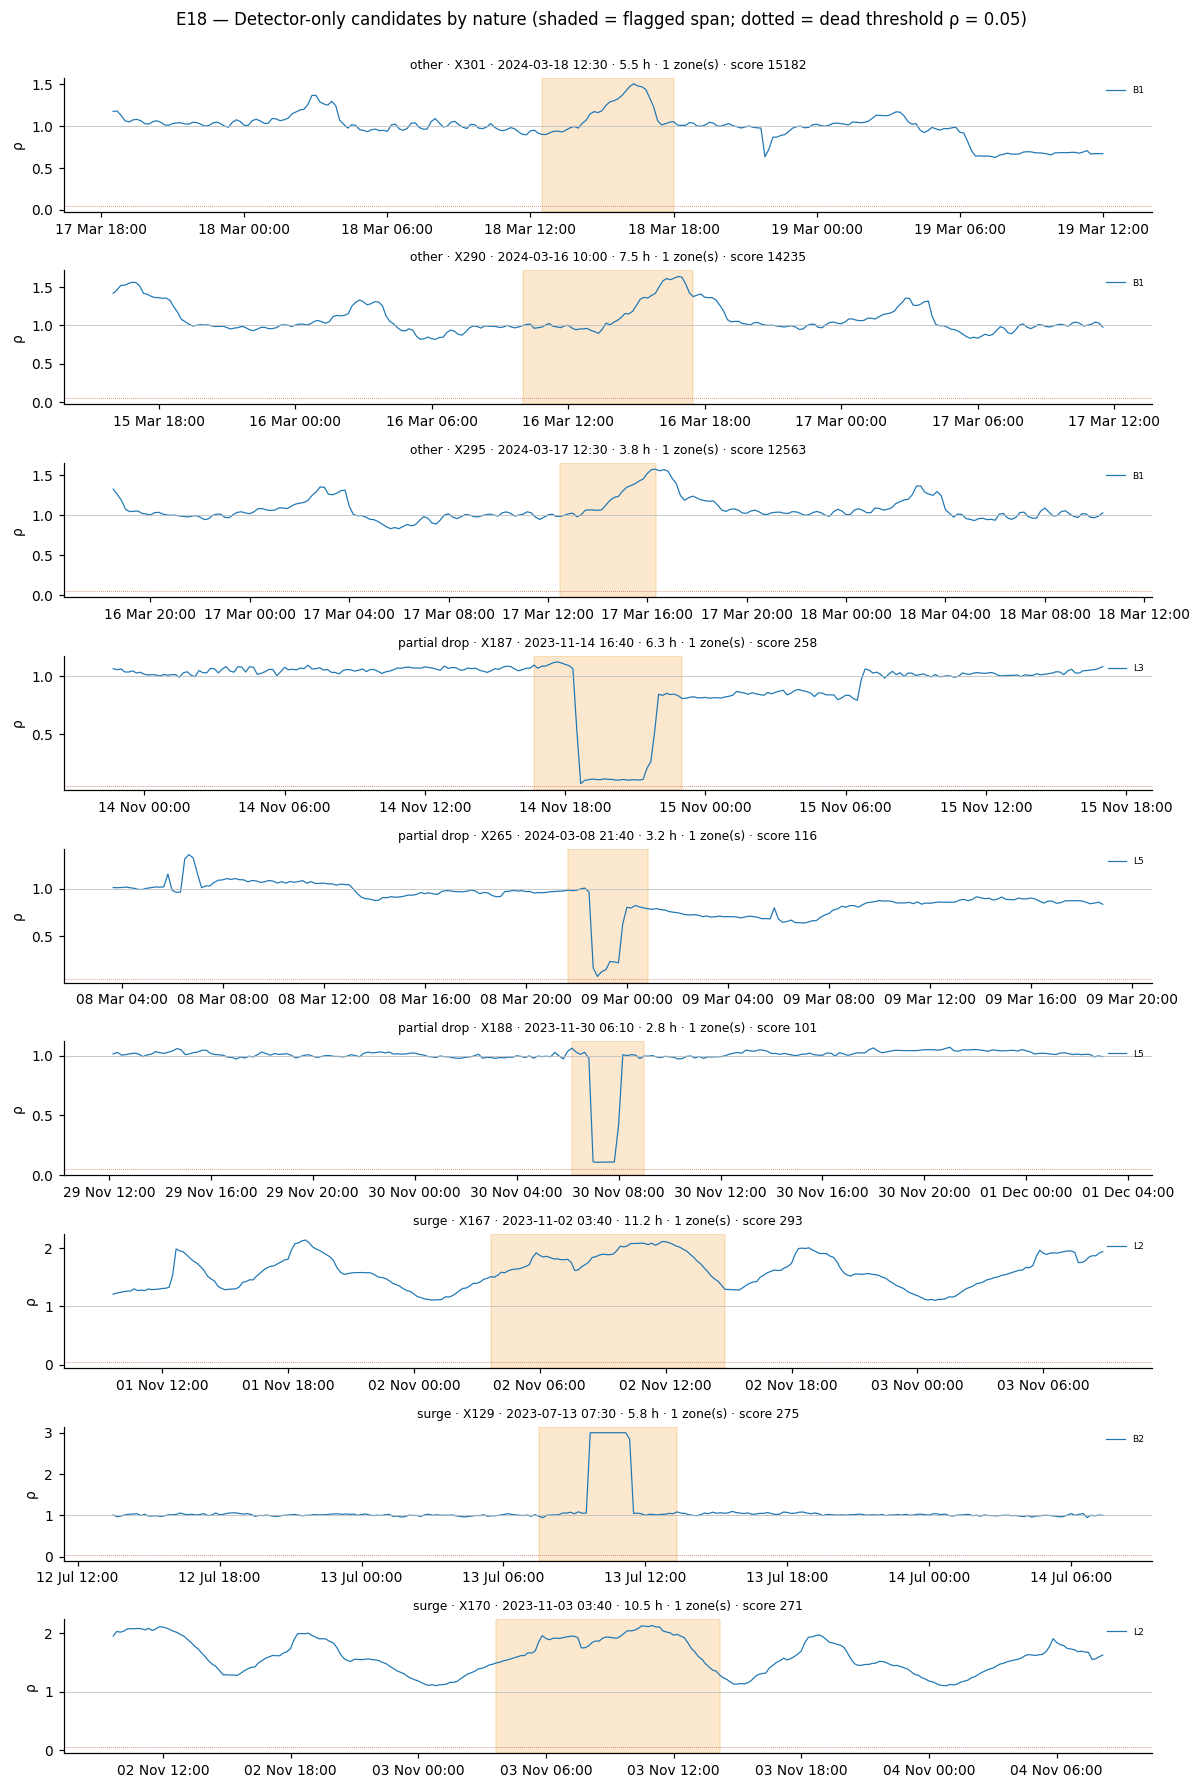

In [11]:
df = feat[feat.source == "detector"].merge(det[["item_id", "start", "end", "zones", "max_score"]], on="item_id")
df["nature"] = np.where((df.rho_mean < 0.7) & (df.rho_min < 0.5), "partial drop", np.where(df.rho_mean > 1.4, "surge", "other"))
nature = df.groupby(["system", "nature"]).agg(n=("item_id", "size"), median_h=("duration_h", "median"), median_rho=("rho_mean", "median"), n_multizone=("n_zones", lambda z: int((z > 1).sum()))).round(2)
nature.to_csv(OUT_D / "detector_only_nature.csv"); det = det.merge(df[["item_id", "nature", "rho_mean", "rho_min"]], on="item_id", how="left")
det.to_csv(OUT_D / "detector_items.csv", index=False)
print(nature.to_string())
show = pd.concat([g.sort_values("max_score", ascending=False).head(3) for _, g in df.groupby("nature")]).head(9)
fig, axs = plt.subplots(len(show), 1, figsize=(11, 1.8 * len(show)))
for ax, r in zip(np.atleast_1d(axs), show.itertuples()):
    P = PAN[r.system]; zs = r.zones.split(",")[:4]
    a, b = r.start - pd.Timedelta(hours=18), r.end + pd.Timedelta(hours=18)
    for z in zs:
        ax.plot(P["rho"][z][a:b], lw=.8, label=z)
    ax.axvspan(r.start, r.end, color="#F2A541", alpha=.25); ax.axhline(1, color="#bbb", lw=.5); ax.axhline(0.05, color="#C8553D", lw=.5, ls=":")
    ax.set_ylabel("ρ"); ax.legend(fontsize=6, loc="upper right", ncol=4)
    ax.set_title(f"{r.nature} · {r.item_id} · {r.start:%Y-%m-%d %H:%M} · {r.duration_h:.1f} h · {r.n_zones} zone(s) · score {r.max_score:.0f}", fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
fig.suptitle("E18 — Detector-only candidates by nature (shaded = flagged span; dotted = dead threshold ρ = 0.05)", y=1.0)
fig.tight_layout(); savefig(fig, FIG, "E18_detector_only_gallery"); plt.show()

## 6. End model (eq. 12): soft-label LightGBM and MLP, out of fold by episode
Targets: q over the event classes for rule items (renormalised; A4 and G5 never occur on dead or fill items) and N for normal windows.
Detector-only candidates are predicted by models trained on all labelled items.

In [12]:
CL = EM.EVENT_CLASSES
DET_COLS = [c for c in feat.columns if c.startswith("det_")]
EP_COLS = ["ep_n_items", "ep_has_multizone_fill", "ep_has_multicity_dead", "ep_duration_h", "preceded_by_fill", "followed_by_fill"]
BASE_COLS = [c for c in feat.columns if c not in DET_COLS + EP_COLS + ["item_id", "system", "source"]]
lab = feat[feat.source != "detector"].reset_index(drop=True)
qi = q.set_index("item_id")
Q = np.zeros((len(lab), len(CL)))
for i, r in enumerate(lab.itertuples()):
    if r.source == "rule":
        Q[i] = [qi.at[r.item_id, f"q_{c}"] for c in CL]
    else:
        Q[i, CL.index("N")] = 1.0
Q = Q / Q.sum(axis=1, keepdims=True)
groups = np.array([qi.at[i, "episode"] if (i in qi.index and isinstance(qi.at[i, "episode"], str)) else i for i in lab.item_id])
GB_BACKEND = "lightgbm" if BACKEND == "lightgbm" else "sklearn"

def run(cols, learner, **kw):
    X = lab[cols].to_numpy(dtype=float)
    return EM.oof_predict(X, Q, groups, learner, **kw)

variants = {
    "GBDT, all features": (BASE_COLS + EP_COLS + DET_COLS, EM.fit_predict_gbdt, dict(backend=GB_BACKEND)),
    "GBDT, no detector features": (BASE_COLS + EP_COLS, EM.fit_predict_gbdt, dict(backend=GB_BACKEND)),
    "GBDT, no episode features": (BASE_COLS + DET_COLS, EM.fit_predict_gbdt, dict(backend=GB_BACKEND)),
    "GBDT, detector features only": (DET_COLS, EM.fit_predict_gbdt, dict(backend=GB_BACKEND)),
    "MLP, all features": (BASE_COLS + EP_COLS + DET_COLS, EM.fit_predict_mlp, {}),
}
OOF = {}
for name, (cols, learner, kw) in variants.items():
    t = time.time(); OOF[name] = run(cols, learner, **kw); print(f"{name}: {time.time() - t:.0f} s")

is_rule = (lab.source == "rule").to_numpy()
qlab = np.array(CL)[Q.argmax(axis=1)]
rows = []
for name, F in OOF.items():
    pl = np.array(CL)[F.argmax(axis=1)]
    rows.append(dict(variant=name, agree_rule_items=(pl[is_rule] == qlab[is_rule]).mean(), normal_windows_as_N=(pl[~is_rule] == "N").mean(),
                     soft_CE_rule=EM.soft_ce(Q[is_rule], F[is_rule]), soft_CE_normal=EM.soft_ce(Q[~is_rule], F[~is_rule]),
                     **{f"agree_{c}": (pl[is_rule & (qlab == c)] == c).mean() if (is_rule & (qlab == c)).any() else np.nan for c in CL}))
em_metrics = pd.DataFrame(rows).round(3)
em_metrics.to_csv(OUT_E / "end_model_metrics.csv", index=False)
em_metrics

GBDT, all features: 8 s
GBDT, no detector features: 3 s
GBDT, no episode features: 5 s
GBDT, detector features only: 7 s
MLP, all features: 14 s


,variant,agree_rule_items,normal_windows_as_N,soft_CE_rule,soft_CE_normal,agree_A1,agree_A2,agree_A3,agree_G1,agree_G2,agree_G3,agree_G4,agree_N
0,"GBDT, all features",0.957,1.00,0.311,0.001,0.667,1.000,1.000,NaN,0.0,0.906,0.971,0.0
1,"GBDT, no detector features",0.954,1.00,0.298,0.002,0.667,1.000,1.000,NaN,0.0,0.868,0.986,0.0
2,"GBDT, no episode features",0.950,1.00,0.316,0.001,0.667,0.982,1.000,NaN,0.0,0.887,0.971,0.0
3,"GBDT, detector features only",0.548,0.97,1.481,0.075,0.333,0.737,0.463,NaN,0.0,0.453,0.623,0.0
4,"MLP, all features",0.925,1.00,0.372,0.000,1.000,0.965,0.989,NaN,0.0,0.830,0.928,0.0


## 7. Fusion (eq. 16) and the final probabilistic labels for event items

In [13]:
BETA = 0.5
F_main = OOF["GBDT, all features"]
feas = np.zeros((len(lab), len(CL)))
for i, r in enumerate(lab.itertuples()):
    allowed = qi.at[r.item_id, "feasible"].split(",") if r.source == "rule" else CL
    feas[i] = [c in allowed for c in CL]
LOW = EM.low_support_classes(Q[is_rule], CL)
abst = np.isin(np.array(CL)[Q.argmax(axis=1)], LOW) & is_rule
print("low-support classes (end model abstains):", LOW, "| items affected:", int(abst.sum()))
Pf = EM.fuse(Q, F_main, feas, beta=BETA, abstain=abst)

cols_all = BASE_COLS + EP_COLS + DET_COLS
Fd = EM.fit_predict_gbdt(lab[cols_all].to_numpy(float), Q, feat[feat.source == "detector"][cols_all].to_numpy(float), CL, backend=GB_BACKEND) if (feat.source == "detector").any() else np.zeros((0, len(CL)))
dsub = feat[feat.source == "detector"].reset_index(drop=True)

def frame(ids, src, Qm, Fm, Pm):
    d = pd.DataFrame({"item_id": ids, "source": src})
    for k, c in enumerate(CL):
        d[f"q_{c}"], d[f"f_{c}"], d[f"p_{c}"] = Qm[:, k].round(4), Fm[:, k].round(4), Pm[:, k].round(4)
    d["label_q"] = np.array(CL)[Qm.argmax(axis=1)]; d["label_f"] = np.array(CL)[Fm.argmax(axis=1)]
    d["label_p"] = np.array(CL)[Pm.argmax(axis=1)]; d["confidence_p"] = Pm.max(axis=1).round(4)
    return d
ptype = frame(lab.item_id, lab.source, Q, F_main, Pf)
if len(dsub):
    unif = np.full((len(dsub), len(CL)), 1 / len(CL))
    ptype = pd.concat([ptype, frame(dsub.item_id, "detector", unif, Fd, EM.fuse(unif, Fd, np.ones_like(Fd), beta=BETA))], ignore_index=True)
ptype.loc[ptype.source == "detector", ["label_q"] + [f"q_{c}" for c in CL]] = np.nan
ptype.to_csv(OUT_E / "p_type.csv", index=False)

rule_pt = ptype[ptype.source == "rule"].merge(q[["item_id", "start", "zones", "votes"]], on="item_id")
changed = rule_pt[rule_pt.label_p != rule_pt.label_q]
print(f"rule items whose fused label differs from the label model: {len(changed)} of {len(rule_pt)}")
print(changed[["item_id", "start", "zones", "votes", "label_q", "label_f", "label_p", "confidence_p"]].to_string(index=False))
print("\ndetector-only candidates, end-model label:", ptype[ptype.source == "detector"].label_f.value_counts().to_dict())

low-support classes (end model abstains): ['A1', 'G1', 'G2'] | items affected: 4
rule items whose fused label differs from the label model: 5 of 281
item_id               start zones           votes label_q label_f label_p  confidence_p
   D098 2023-08-06 07:00:00    B2      R5:G;R9:G3      G3      G4      G4        0.6040
   D109 2023-12-24 05:50:00    L3 R5:G;R6:G;R9:G3      G3      G4      G4        0.5633
   F126 2023-12-24 05:50:00    L2             NaN       N      A3      A3        0.9837
   F127 2023-12-24 06:20:00    L3             NaN       N      A3      A3        0.9898
   F147 2024-04-06 09:20:00    L1             NaN       N      A3      A3        0.9361

detector-only candidates, end-model label: {'N': 304, 'A3': 12, 'G4': 7}


saved /content/drive/MyDrive/grid-event-or-data-artefact/results/figures/E19_end_model.png


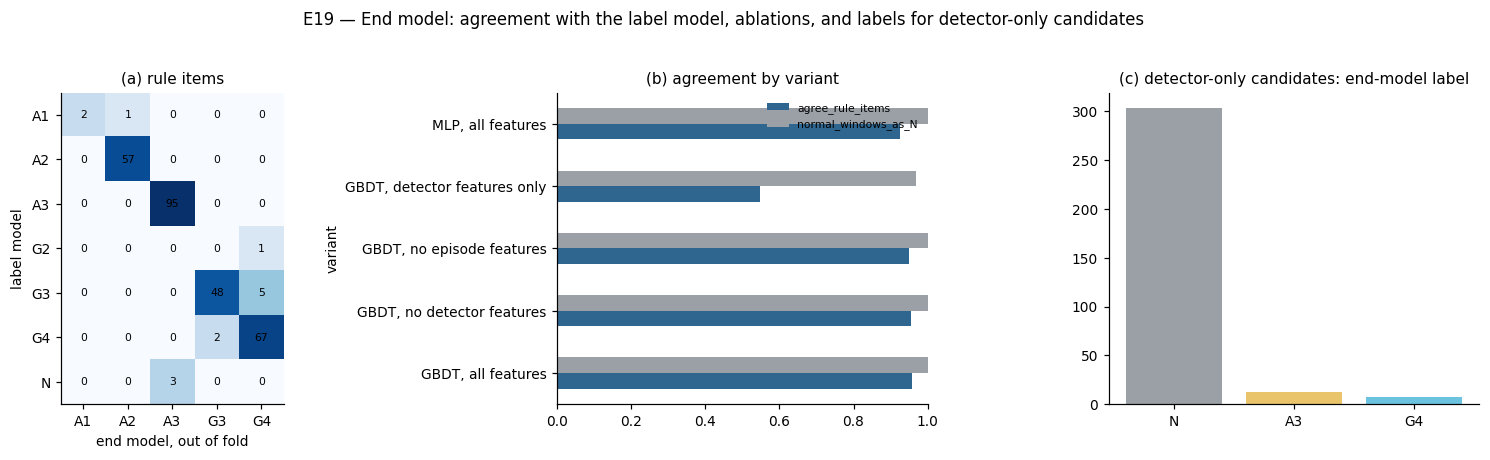

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
cm = pd.crosstab(pd.Series(qlab[is_rule], name="label model"), pd.Series(np.array(CL)[F_main.argmax(axis=1)][is_rule], name="end model (OOF)"))
im = axs[0].imshow(np.log1p(cm.values), cmap="Blues")
axs[0].set_xticks(range(cm.shape[1])); axs[0].set_xticklabels(cm.columns); axs[0].set_yticks(range(cm.shape[0])); axs[0].set_yticklabels(cm.index)
for (i, j), v in np.ndenumerate(cm.values): axs[0].text(j, i, v, ha="center", va="center", fontsize=7)
axs[0].set_xlabel("end model, out of fold"); axs[0].set_ylabel("label model"); axs[0].set_title("(a) rule items")
em_plot = em_metrics.set_index("variant")[["agree_rule_items", "normal_windows_as_N"]]
em_plot.plot.barh(ax=axs[1], color=["#2F6690", "#9AA0A6"]); axs[1].set_xlim(0, 1); axs[1].legend(fontsize=7); axs[1].set_title("(b) agreement by variant")
dl = ptype[ptype.source == "detector"].label_f.value_counts()
axs[2].bar(dl.index, dl.values, color=[LABEL_COL.get(c, "#999") for c in dl.index]); axs[2].set_title("(c) detector-only candidates: end-model label")
fig.suptitle("E19 — End model: agreement with the label model, ablations, and labels for detector-only candidates", y=1.03)
fig.tight_layout(); savefig(fig, FIG, "E19_end_model"); plt.show()

## 8. Summary (copied into docs/results_summary.md)

In [15]:
summary = dict(backend=BACKEND, main_residual=MAIN, gamma={k: round(v, 3) for k, v in GAMMA.items()},
               predictor_MAE={f"{r.system} | {r.residual}": r.MAE for r in pred_metrics[pred_metrics.period == "all"].itertuples()},
               hierarchy_consistency=hier.set_index("residual")["all"].to_dict(),
               detector_only_candidates=int(len(det)), normal_windows=int(len(nw)),
               end_model=em_metrics.set_index("variant")[["agree_rule_items", "normal_windows_as_N"]].to_dict(orient="index"),
               fused_changes=int(len(changed)), low_support_classes=LOW,
               detector_only_nature=det.nature.value_counts().to_dict(),
               detector_recall={f"{k[0]} | {k[1]}": v for k, v in recall.detected.items()}, runtime_min=round((time.time() - T0) / 60, 1))
summary = json.loads(json.dumps(summary, default=lambda o: str(o)))
(OUT_E / "summary.json").write_text(json.dumps(summary, indent=2))
summary

{'backend': 'lightgbm',
 'main_residual': 'forecast',
 'gamma': {'south': 33.348, 'Marrakech': 16.882},
 'predictor_MAE': {'south | forecast': 0.0288,
  'south | nowcast': 0.0292,
  'south | expected (rho_hat = 1)': 0.1835,
  'south | STL': 0.0594,
  'Marrakech | forecast': 0.1076,
  'Marrakech | nowcast': 0.1077,
  'Marrakech | expected (rho_hat = 1)': 0.2755},
 'hierarchy_consistency': {'forecast': 0.772, 'nowcast': 0.791, 'STL': 0.699},
 'detector_only_candidates': 323,
 'normal_windows': 300,
 'end_model': {'GBDT, all features': {'agree_rule_items': 0.957,
   'normal_windows_as_N': 1.0},
  'GBDT, no detector features': {'agree_rule_items': 0.954,
   'normal_windows_as_N': 1.0},
  'GBDT, no episode features': {'agree_rule_items': 0.95,
   'normal_windows_as_N': 1.0},
  'GBDT, detector features only': {'agree_rule_items': 0.548,
   'normal_windows_as_N': 0.97},
  'MLP, all features': {'agree_rule_items': 0.925,
   'normal_windows_as_N': 1.0}},
 'fused_changes': 5,
 'low_support_class